# 05 · Лучшие модели, ошибки и неопределённость · v2
## tl;dr
Основная процедура **C_ovr/single**: test macro-F1 **0.8538**, recall патологического класса **91.4%**, AP **0.9103**. При равном суммарном весе каждого исходного файла macro-F1 **0.8676**, recall патологии **85.8%**. Эти метрики описывают разные единицы усреднения. Test был известен до аудита; внешняя клиническая проверка не заменена.

## Context & Methods

Основной результат выбран без нового test. Macro-F1, recall/AP патологического класса и proper probability scores нужны вместе. AP — Average Precision, не трапецеидальная площадь под PR-кривой. Bootstrap по исходным файлам отражает неопределённость состава данного test для фиксированной модели; он не оценивает весь разброс обучения или переноса на другую клинику. NSP — экспертная разметка КТГ, а не наблюдаемый исход.

In [3]:
from pathlib import Path
import sys,json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.training.ctg_audit import (AUDIT,EXPORT,context,CTG_FEATURES,score,soft_vote)
data,fingerprint,cache=context()
sns.set_theme(style='whitegrid',font_scale=1.05)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'figure.figsize':(10,5)})
def show_save(name):
    plt.gcf().savefig(AUDIT/name,dpi=140,bbox_inches='tight')
    plt.show()

## Data & Results

In [5]:
results=pd.read_csv(AUDIT/'test_metrics.csv');locked=json.loads((AUDIT/'locked_decision.json').read_text())
predictions=pd.read_parquet(AUDIT/'test_predictions.parquet')
primary=locked['primary'];shortlist=locked['shortlist']
display(results.round(4))
test=data[data.split=='test'].reset_index(drop=True)
prior=data[data.split=='train'].NSP.value_counts(normalize=True).reindex([1,2,3]).to_numpy()
baseline=score(test,np.tile(prior,(len(test),1)))
display(pd.Series(baseline,name='always_normal').to_frame().round(4))

,candidate,primary,shortlisted,accuracy,macro_f1,balanced_accuracy,recall_path,precision_path,f1_path,recall_normal,recall_suspect,ap_path,roc_auc_path,log_loss,brier,path_as_normal,specificity_path,file_macro_f1,file_recall_path,file_log_loss,file_ap_path
0,A_multiclass/single,False,False,0.9176,0.8511,0.8587,0.9143,0.7805,0.8421,0.9548,0.7069,0.9395,0.9876,0.2033,0.1109,0.0286,0.9769,0.8645,0.8576,0.2363,0.9325
1,B_sqrt/single,False,False,0.9365,0.8806,0.8667,0.9143,0.8649,0.8889,0.9789,0.7069,0.9222,0.9873,0.1980,0.1030,0.0286,0.9872,0.8789,0.8576,0.2338,0.9358
2,B_balanced/single,False,False,0.9365,0.8838,0.8857,0.9143,0.8421,0.8767,0.9669,0.7759,0.9089,0.9845,0.2013,0.1041,0.0286,0.9846,0.8829,0.8576,0.2317,0.9321
3,C_ovr/single,True,True,0.9224,0.8538,0.8607,0.9143,0.7619,0.8312,0.9608,0.7069,0.9103,0.9859,0.2143,0.1127,0.0286,0.9744,0.8676,0.8576,0.2408,0.9116
4,C_ovr/fold_ensemble,False,False,0.9247,0.8593,0.8664,0.9143,0.7805,0.8421,0.9608,0.7241,0.9284,0.9874,0.2099,0.1107,0.0286,0.9769,0.8707,0.8576,0.2320,0.9239
5,D_hierarchy/single,False,True,0.9129,0.8454,0.8519,0.9143,0.8000,0.8533,0.9518,0.6897,0.9403,0.9855,0.2193,0.1222,0.0286,0.9795,0.8589,0.8576,0.2483,0.9136
6,D_hierarchy/fold_ensemble,False,False,0.9106,0.8413,0.8557,0.9143,0.7619,0.8312,0.9458,0.7069,0.9299,0.9847,0.2226,0.1233,0.0286,0.9744,0.8597,0.8576,0.2517,0.9062
7,logistic/single,False,False,0.8894,0.7748,0.7510,0.6571,0.8214,0.7302,0.9578,0.6379,0.8059,0.9823,0.2683,0.1612,0.1714,0.9872,0.7348,0.5200,0.3276,0.6570


,always_normal
accuracy,0.7812
macro_f1,0.2924
balanced_accuracy,0.3333
recall_path,0.0000
precision_path,0.0000
f1_path,0.0000
recall_normal,1.0000
recall_suspect,0.0000
ap_path,0.0824
roc_auc_path,0.5000


### Матрицы ошибок shortlist

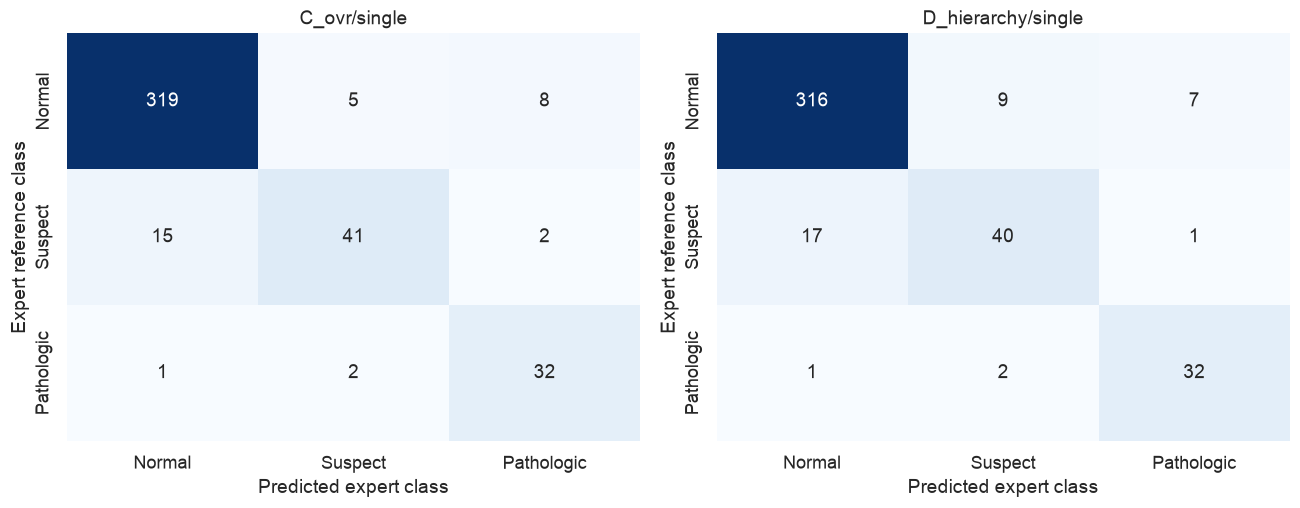

In [7]:
from sklearn.metrics import confusion_matrix,average_precision_score,precision_recall_curve,roc_curve
fig,axes=plt.subplots(1,len(shortlist),figsize=(6*len(shortlist),4.8),squeeze=False)
for ax,candidate in zip(axes[0],shortlist):
    p=predictions[predictions.candidate==candidate]
    sns.heatmap(confusion_matrix(p.NSP,p.pred,labels=[1,2,3]),annot=True,fmt='d',cmap='Blues',
        xticklabels=['Normal','Suspect','Pathologic'],yticklabels=['Normal','Suspect','Pathologic'],ax=ax,cbar=False)
    ax.set(title=candidate,xlabel='Predicted expert class',ylabel='Expert reference class')
fig.tight_layout();show_save('03_confusion.png')

### Распознавание патологического класса

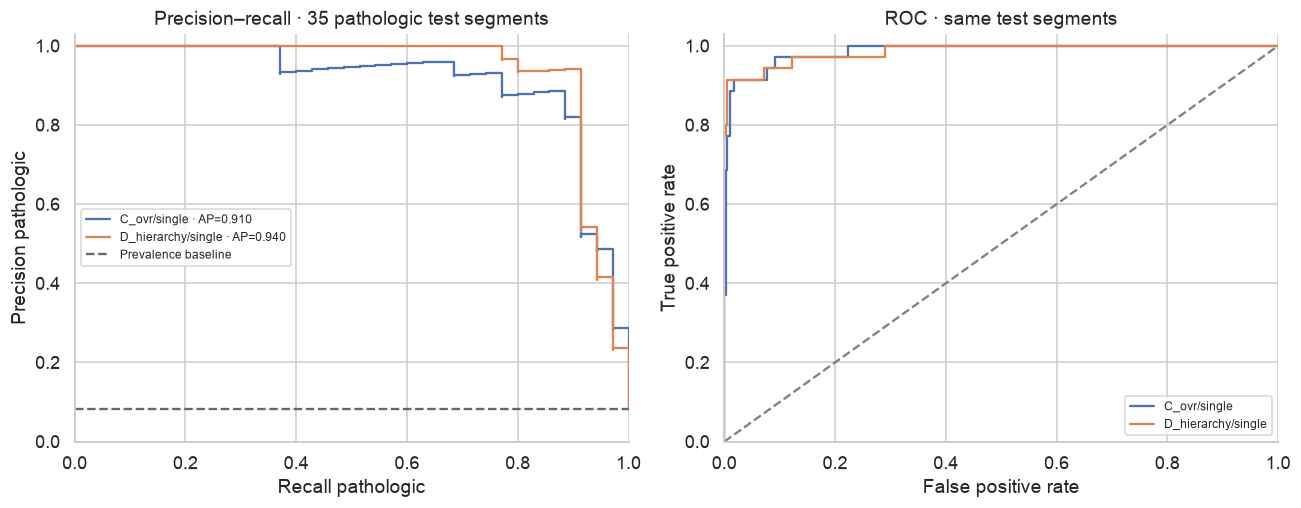

In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
for candidate in shortlist:
    p=predictions[predictions.candidate==candidate];y=p.NSP.to_numpy()==3
    precision,recall,_=precision_recall_curve(y,p.p2)
    axes[0].step(recall,precision,where='post',label=f'{candidate} · AP={average_precision_score(y,p.p2):.3f}')
    fpr,tpr,_=roc_curve(y,p.p2);axes[1].plot(fpr,tpr,label=candidate)
axes[0].axhline((test.NSP==3).mean(),ls='--',color='.4',label='Prevalence baseline')
axes[1].plot([0,1],[0,1],'--',color='.5')
axes[0].set(xlabel='Recall pathologic',ylabel='Precision pathologic',title='Precision–recall · 35 pathologic test segments')
axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC · same test segments')
for ax in axes:ax.legend(fontsize=8);ax.set_xlim(0,1);ax.set_ylim(0,1.03)
fig.tight_layout();show_save('04_path_curves.png')

### Описательная проверка вероятностей

Пять квантильных групп вероятностей на известном test. Точки показывают средний прогноз и наблюдаемую долю экспертного класса; это не доказательство идеальной калибровки. Log loss/Brier учитывают также различимость и неопределённость данных, поэтому не являются чистой мерой калибровки. Сегменты одной записи зависимы; полосы независимых биномиальных ошибок здесь не используются.

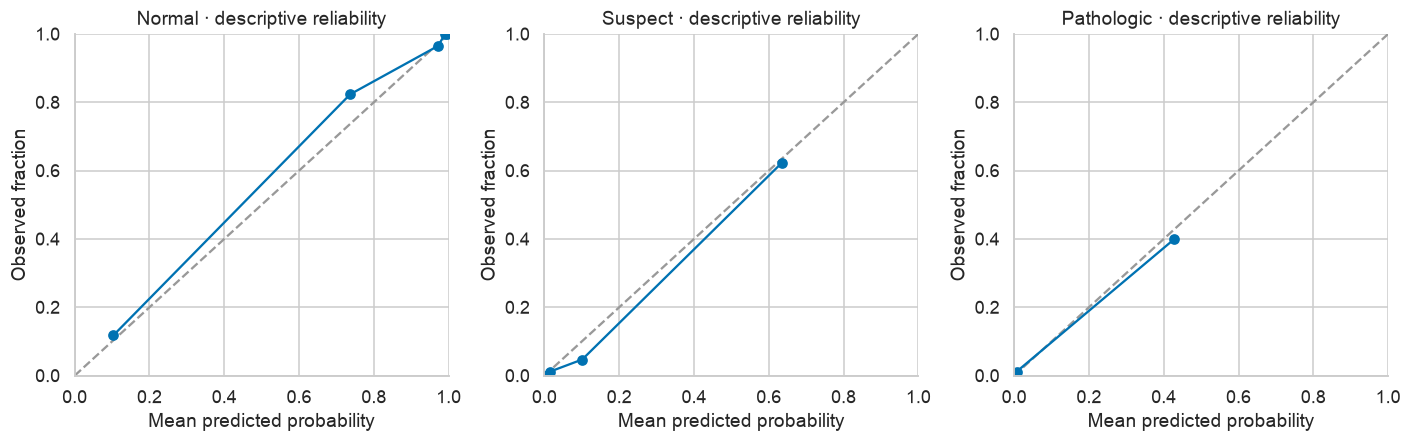

In [11]:
p=predictions[predictions.candidate==primary].copy()
fig,axes=plt.subplots(1,3,figsize=(13,4.2))
for j,(ax,name) in enumerate(zip(axes,['Normal','Suspect','Pathologic'])):
    bins=pd.qcut(p[f'p{j}'],q=5,duplicates='drop')
    tab=pd.DataFrame({'bin':bins,'probability':p[f'p{j}'],'observed':p.NSP==j+1}).groupby('bin',observed=True).agg(mean_probability=('probability','mean'),fraction=('observed','mean'),segments=('observed','size'))
    ax.plot([0,1],[0,1],'--',color='.6');ax.plot(tab.mean_probability,tab.fraction,'o-',color='#0072b2')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed fraction',title=f'{name} · descriptive reliability')
fig.tight_layout();show_save('05_probability_reliability.png')

### Неопределённость и вклад исходных записей

In [13]:
display(pd.read_csv(AUDIT/'test_paired_intervals.csv').round(4))
p=predictions[predictions.candidate==primary].copy()
p['path_true']=p.NSP==3;p['path_found']=(p.NSP==3)&(p.pred==3)
support=p[p.NSP==3].groupby('source_file').agg(path_segments=('path_true','sum'),found=('path_found','sum'))
support['recall']=support.found/support.path_segments
display(support)
support.to_csv(AUDIT/'pathologic_recording_errors.csv')
comparison=results[results.shortlisted].set_index('candidate')[['macro_f1','file_macro_f1','recall_path','file_recall_path']]
display(comparison.round(4))

,candidate,macro_f1,recall_path,macro_f1_low,macro_f1_high,recall_low,recall_high,delta_macro_f1_vs_primary,delta_low,delta_high
0,C_ovr/single,0.8538,0.9143,0.7580,0.9154,0.7028,1.0,0.0000,0.0000,0.0000
1,D_hierarchy/single,0.8454,0.9143,0.7466,0.9061,0.7028,1.0,-0.0083,-0.0351,0.0133


,path_segments,found,recall
source_file,,,
Aast_12.txt,1,1,1.000000
Mabp_12.txt,3,3,1.000000
Mabp_25.txt,3,2,0.666667
Mabp_7.txt,2,2,1.000000
Mjmar_3.txt,1,1,1.000000
Mmbms_18.txt,2,1,0.500000
Mmmfm_1.txt,2,2,1.000000
S0001072.dat,4,4,1.000000
S7001018.dsp,1,0,0.000000


,macro_f1,file_macro_f1,recall_path,file_recall_path
candidate,,,,
C_ovr/single,0.8538,0.8676,0.9143,0.8576
D_hierarchy/single,0.8454,0.8589,0.9143,0.8576


### Независимый пересчёт и roundtrip всех текущих моделей

In [15]:
from sklearn.metrics import f1_score,log_loss,recall_score
checked=[]
for candidate,part in predictions.groupby('candidate'):
    row=results[results.candidate==candidate].iloc[0]
    p=part[['p0','p1','p2']].to_numpy();y=part.NSP.to_numpy()-1
    np.testing.assert_allclose(p.sum(axis=1),1,atol=1e-12)
    assert abs(f1_score(y,part.pred.to_numpy()-1,average='macro')-row.macro_f1)<1e-12
    assert abs(recall_score(y==2,part.pred.to_numpy()==3)-row.recall_path)<1e-12
    assert abs(average_precision_score(y==2,p[:,2])-row.ap_path)<1e-12
    assert abs(log_loss(y,p,labels=[0,1,2])-row.log_loss)<1e-12
    model=joblib.load(EXPORT/f'{candidate.replace("/","_")}.joblib')
    frame=data.set_index('source_excel_row').loc[part.source_excel_row]
    np.testing.assert_allclose(model.predict_proba(frame[list(CTG_FEATURES)]),p,atol=1e-12)
    np.testing.assert_array_equal(model.predict(frame[list(CTG_FEATURES)]),part.pred)
    checked.append(candidate)
print('Independently checked:',checked)

Independently checked: ['A_multiclass/single', 'B_balanced/single', 'B_sqrt/single', 'C_ovr/fold_ensemble', 'C_ovr/single', 'D_hierarchy/fold_ensemble', 'D_hierarchy/single', 'logistic/single']


## Takeaways

Результаты характеризуют данную выборку и процедуры. Длинные записи не являются множеством независимых пациенток; поэтому рядом показаны поддержка исходными файлами и file-balanced метрики. Клиническая применимость и превосходство на другом источнике здесь не установлены.